In [1]:
# ─────────────────────────────────────────────
# STEP 1: Install & Import Libraries
# ─────────────────────────────────────────────
# Run this in Colab first:
# !pip install kaggle

import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import warnings
warnings.filterwarnings('ignore')

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (Conv2D, MaxPooling2D, GlobalAveragePooling2D,
                                      Dense, Dropout, BatchNormalization)
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                              accuracy_score, precision_score,
                              recall_score, f1_score)

print("TensorFlow version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.20.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
# ─────────────────────────────────────────────
# STEP 2: Upload & Extract Dataset
# ─────────────────────────────────────────────
import zipfile
from google.colab import files

print("Please select your dataset ZIP file from your computer...")
uploaded = files.upload()

# Automatically get the exact name of the file you just uploaded
zip_filename = list(uploaded.keys())[0]

# Extract it EXACTLY to the folder name expected in STEP 3
extract_to_dir = "brain_tumor_dataset"

with zipfile.ZipFile(zip_filename, "r") as zip_ref:
    zip_ref.extractall(extract_to_dir)

print(f"Success! Dataset extracted to '{extract_to_dir}' folder.")

Please select your dataset ZIP file from your computer...


Saving brain_mri_data.zip to brain_mri_data (1).zip
Success! Dataset extracted to 'brain_tumor_dataset' folder.


In [6]:
# ─────────────────────────────────────────────
# STEP 3: Load & Preprocess Data
# ─────────────────────────────────────────────

IMG_SIZE = 224       # Resize all images to 224x224
BATCH_SIZE = 32
EPOCHS = 25
LEARNING_RATE = 0.001

# Dataset paths — adjust if your folder structure differs
DATA_DIR = "brain_tumor_dataset/brain_mri_data"
YES_DIR = os.path.join(DATA_DIR, "yes")
NO_DIR  = os.path.join(DATA_DIR, "no")

def load_images(folder, label):
    """Load all images from a folder and assign a binary label."""
    images, labels = [], []
    for filename in os.listdir(folder):
        if filename.lower().endswith(('.jpg', '.jpeg', '.png')):
            path = os.path.join(folder, filename)
            img = cv2.imread(path)
            if img is None:
                continue
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
            images.append(img)
            labels.append(label)
    return images, labels

print("Loading images...")
tumor_images, tumor_labels = load_images(YES_DIR, label=1)
normal_images, normal_labels = load_images(NO_DIR, label=0)

print(f"  Tumor images:    {len(tumor_images)}")
print(f"  No-tumor images: {len(normal_images)}")

# Combine and convert to numpy arrays
X = np.array(tumor_images + normal_images, dtype=np.float32)
y = np.array(tumor_labels + normal_labels, dtype=np.float32)

# Normalize pixel values to [0, 1]
X = X / 255.0

print(f"\nDataset shape: {X.shape}")
print(f"Labels — Tumor: {np.sum(y==1)}, No Tumor: {np.sum(y==0)}")

Loading images...
  Tumor images:    155
  No-tumor images: 98

Dataset shape: (253, 224, 224, 3)
Labels — Tumor: 155, No Tumor: 98


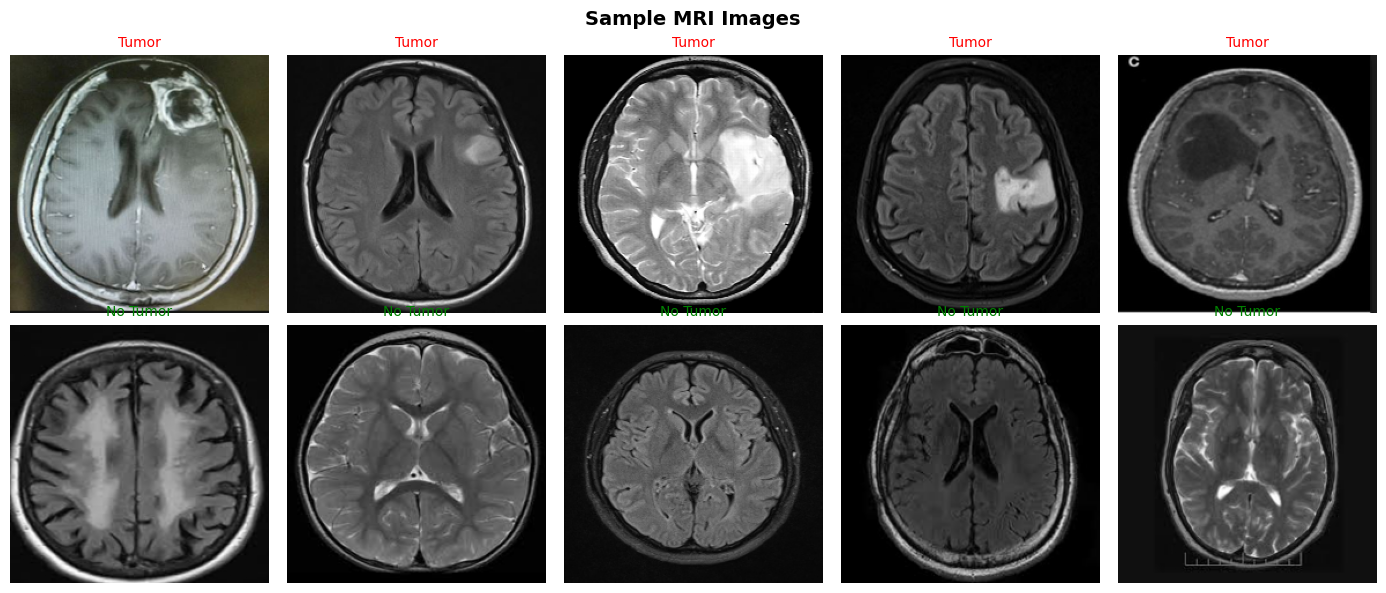

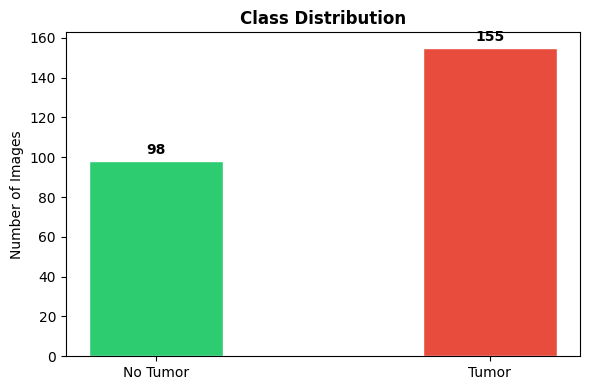

In [7]:
# ─────────────────────────────────────────────
# STEP 4: Exploratory Data Analysis (EDA)
# ─────────────────────────────────────────────

# Plot sample images
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
fig.suptitle("Sample MRI Images", fontsize=14, fontweight='bold')

for i, ax in enumerate(axes[0]):
    idx = np.where(y == 1)[0][i]
    ax.imshow(X[idx])
    ax.set_title("Tumor", color='red', fontsize=10)
    ax.axis('off')

for i, ax in enumerate(axes[1]):
    idx = np.where(y == 0)[0][i]
    ax.imshow(X[idx])
    ax.set_title("No Tumor", color='green', fontsize=10)
    ax.axis('off')

plt.tight_layout()
plt.savefig("sample_images.png", dpi=150, bbox_inches='tight')
plt.show()

# Class distribution bar chart
fig, ax = plt.subplots(figsize=(6, 4))
classes = ['No Tumor', 'Tumor']
counts  = [int(np.sum(y==0)), int(np.sum(y==1))]
colors  = ['#2ecc71', '#e74c3c']
bars = ax.bar(classes, counts, color=colors, width=0.4, edgecolor='white')
for bar, count in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2,
            str(count), ha='center', va='bottom', fontweight='bold')
ax.set_title("Class Distribution", fontweight='bold')
ax.set_ylabel("Number of Images")
plt.tight_layout()
plt.savefig("class_distribution.png", dpi=150, bbox_inches='tight')
plt.show()

In [8]:
# ─────────────────────────────────────────────
# STEP 5: Train / Test Split
# ─────────────────────────────────────────────

# First split: Separate out 20% for TEST (unseen until the very end)
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
# Second split: Take the remaining 80% and split 25% off for VALIDATION
# (0.25 * 0.80 = 0.20, resulting in 60% Train, 20% Val, 20% Test)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, random_state=42, stratify=y_train_val
)
print(f"Training samples: {len(X_train)}")
print(f"Validation samples: {len(X_val)}")
print(f"Testing samples:  {len(X_test)}")

Training samples: 151
Validation samples: 51
Testing samples:  51


In [9]:
# ─────────────────────────────────────────────
# STEP 6: Data Augmentation
# ─────────────────────────────────────────────

train_datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

# No augmentation for validation and test sets — only rescaling (already done)
val_datagen = ImageDataGenerator()
test_datagen = ImageDataGenerator()

train_generator = train_datagen.flow(X_train, y_train, batch_size=BATCH_SIZE)
val_generator   = val_datagen.flow(X_val,   y_val,   batch_size=BATCH_SIZE, shuffle=False)
test_generator  = test_datagen.flow(X_test,  y_test,  batch_size=BATCH_SIZE, shuffle=False)

print("Data augmentation configured.")

Data augmentation configured.


In [10]:
# ─────────────────────────────────────────────
# STEP 7: Build CNN Model Architecture
# ─────────────────────────────────────────────

def build_cnn_model(input_shape=(224, 224, 3)):
    """
    Custom CNN for binary brain tumor classification.

    Architecture:
    - 3 convolutional blocks (Conv2D + BatchNorm + MaxPooling)
    - Flatten + Dense layers
    - Dropout for regularization
    - Sigmoid output for binary classification
    """
    model = Sequential([

        # ── Block 1 ──────────────────────────
        Conv2D(32, (3, 3), activation='relu', padding='same',
               input_shape=input_shape, name='conv1'),
        BatchNormalization(name='bn1'),
        MaxPooling2D((2, 2), name='pool1'),

        # ── Block 2 ──────────────────────────
        Conv2D(64, (3, 3), activation='relu', padding='same', name='conv2'),
        BatchNormalization(name='bn2'),
        MaxPooling2D((2, 2), name='pool2'),

        # ── Block 3 ──────────────────────────
        Conv2D(128, (3, 3), activation='relu', padding='same', name='conv3'),
        BatchNormalization(name='bn3'),
        MaxPooling2D((2, 2), name='pool3'),

        # ── Classifier ───────────────────────
        GlobalAveragePooling2D(name='gap'),
        Dense(256, activation='relu', name='fc1'),
        Dropout(0.5, name='dropout'),
        Dense(1, activation='sigmoid', name='output')   # Binary: 0 or 1
    ], name='BrainTumorCNN')

    return model

model = build_cnn_model()
model.summary()

Model: "BrainTumorCNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1 (BatchNormalization)        │ (None, 224, 224, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2 (BatchNormalization)        │ (None, 112, 112, 64)   │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3 (BatchNormalization)        │ (None, 56, 56, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 127,425 (497.75 KB)

 Trainable params: 126,977 (496.00 KB)

 Non-trainable params: 448 (1.75 KB)

In [11]:
# ─────────────────────────────────────────────
# STEP 8: Compile the Model
# ─────────────────────────────────────────────

model.compile(
    optimizer=Adam(learning_rate=LEARNING_RATE),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully.")

Model compiled successfully.


In [12]:
# ─────────────────────────────────────────────
# STEP 9: Define Callbacks
# ─────────────────────────────────────────────

callbacks = [
    # Stop training early if validation loss stops improving
    EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    # Save the best model checkpoint
    ModelCheckpoint(
        filepath='brain_tumor_model.keras',
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    ),
    # Reduce learning rate when validation loss plateaus
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    )
]

print("Callbacks configured.")

Callbacks configured.


In [13]:
# ─────────────────────────────────────────────
# STEP 10: Train the Model
# ─────────────────────────────────────────────

print("\n" + "="*50)
print("Starting model training...")
print("="*50 + "\n")

history = model.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=val_generator,
    callbacks=callbacks,
    verbose=1
)

print("\nTraining complete!")


Starting model training...

Epoch 1/25
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6694 - loss: 0.6034
Epoch 1: val_loss improved from None to 0.67797, saving model to brain_tumor_model.keras

Epoch 1: finished saving model to brain_tumor_model.keras
5/5 ━━━━━━━━━━━━━━━━━━━━ 19s 2s/step - accuracy: 0.6954 - loss: 0.6049 - val_accuracy: 0.6078 - val_loss: 0.6780 - learning_rate: 0.0010
Epoch 2/25
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 312ms/step - accuracy: 0.7164 - loss: 0.5433
Epoch 2: val_loss did not improve from 0.67797
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 340ms/step - accuracy: 0.7020 - loss: 0.5946 - val_accuracy: 0.6078 - val_loss: 0.6781 - learning_rate: 0.0010
Epoch 3/25
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 652ms/step - accuracy: 0.7124 - loss: 0.5765
Epoch 3: val_loss did not improve from 0.67797
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 696ms/step - accuracy: 0.7219 - loss: 0.5558 - val_accuracy: 0.6078 - val_loss: 0.6783 - learning_rate: 0.0010
Epoch 4/25
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 336ms/step - accuracy: 0.7

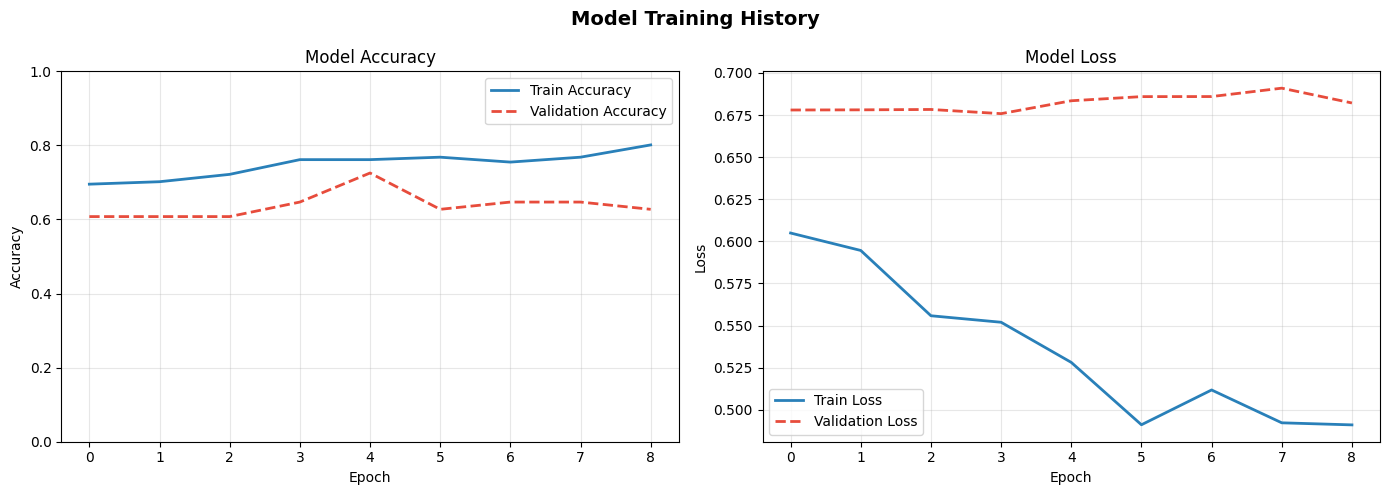

Saved: training_curves.png


In [14]:
# ─────────────────────────────────────────────
# STEP 11: Plot Training Curves
# ─────────────────────────────────────────────

def plot_training_history(history):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle('Model Training History', fontsize=14, fontweight='bold')

    # Accuracy
    ax1.plot(history.history['accuracy'],     label='Train Accuracy',      color='#2980b9', linewidth=2)
    ax1.plot(history.history['val_accuracy'], label='Validation Accuracy', color='#e74c3c', linewidth=2, linestyle='--')
    ax1.set_title('Model Accuracy')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Accuracy')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    ax1.set_ylim([0, 1])

    # Loss
    ax2.plot(history.history['loss'],     label='Train Loss',      color='#2980b9', linewidth=2)
    ax2.plot(history.history['val_loss'], label='Validation Loss', color='#e74c3c', linewidth=2, linestyle='--')
    ax2.set_title('Model Loss')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Loss')
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig("training_curves.png", dpi=150, bbox_inches='tight')
    plt.show()
    print("Saved: training_curves.png")

plot_training_history(history)

In [15]:
# ─────────────────────────────────────────────
# STEP 12: Evaluate the Model
# ─────────────────────────────────────────────

print("\n" + "="*50)
print("Model Evaluation on Test Set")
print("="*50)

# Predict on test set
y_pred_prob = model.predict(X_test, verbose=0).flatten()
y_pred = (y_pred_prob >= 0.5).astype(int)

# Metrics
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
precision = precision_score(y_test, y_pred)
recall    = recall_score(y_test, y_pred)
f1        = f1_score(y_test, y_pred)

print(f"\n  Test Accuracy  : {test_acc:.4f} ({test_acc*100:.2f}%)")
print(f"  Test Loss      : {test_loss:.4f}")
print(f"  Precision      : {precision:.4f}")
print(f"  Recall         : {recall:.4f}")
print(f"  F1-Score       : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['No Tumor', 'Tumor']))


Model Evaluation on Test Set

  Test Accuracy  : 0.6863 (68.63%)
  Test Loss      : 0.6796
  Precision      : 0.6744
  Recall         : 0.9355
  F1-Score       : 0.7838

Classification Report:
              precision    recall  f1-score   support

    No Tumor       0.75      0.30      0.43        20
       Tumor       0.67      0.94      0.78        31

    accuracy                           0.69        51
   macro avg       0.71      0.62      0.61        51
weighted avg       0.70      0.69      0.64        51



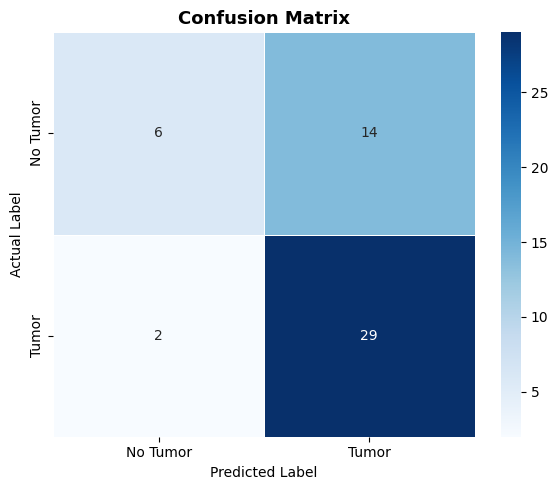

Saved: confusion_matrix.png

  True Positives  (Tumor correctly detected): 29
  True Negatives  (No tumor correctly rejected): 6
  False Positives (Healthy flagged as tumor): 14
  False Negatives (Tumor MISSED — critical!): 2


In [16]:
# ─────────────────────────────────────────────
# STEP 13: Confusion Matrix
# ─────────────────────────────────────────────

def plot_confusion_matrix(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['No Tumor', 'Tumor'],
                yticklabels=['No Tumor', 'Tumor'],
                linewidths=0.5, ax=ax)
    ax.set_title('Confusion Matrix', fontweight='bold', fontsize=13)
    ax.set_ylabel('Actual Label')
    ax.set_xlabel('Predicted Label')
    plt.tight_layout()
    plt.savefig("confusion_matrix.png", dpi=150, bbox_inches='tight')
    plt.show()
    print("Saved: confusion_matrix.png")

    tn, fp, fn, tp = cm.ravel()
    print(f"\n  True Positives  (Tumor correctly detected): {tp}")
    print(f"  True Negatives  (No tumor correctly rejected): {tn}")
    print(f"  False Positives (Healthy flagged as tumor): {fp}")
    print(f"  False Negatives (Tumor MISSED — critical!): {fn}")

plot_confusion_matrix(y_test, y_pred)


Retraining Custom CNN WITH Class Weights...

Calculated Class Weights: {0: np.float64(1.3017241379310345), 1: np.float64(0.8118279569892473)}

Epoch 1/25
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 954ms/step - accuracy: 0.6267 - loss: 0.6312
Epoch 1: val_loss improved from None to 0.68793, saving model to brain_tumor_model_weighted.keras

Epoch 1: finished saving model to brain_tumor_model_weighted.keras
5/5 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - accuracy: 0.6490 - loss: 0.6297 - val_accuracy: 0.6078 - val_loss: 0.6879 - learning_rate: 0.0010
Epoch 2/25
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 310ms/step - accuracy: 0.6630 - loss: 0.6277
Epoch 2: val_loss improved from 0.68793 to 0.68602, saving model to brain_tumor_model_weighted.keras

Epoch 2: finished saving model to brain_tumor_model_weighted.keras
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 367ms/step - accuracy: 0.6556 - loss: 0.6211 - val_accuracy: 0.6275 - val_loss: 0.6860 - learning_rate: 0.0010
Epoch 3/25
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 487ms/step - accuracy: 0.7228 - loss: 

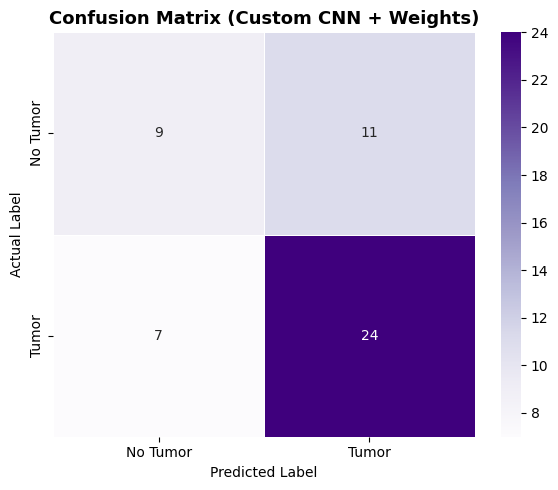

In [18]:
# ─────────────────────────────────────────────
# STEP 13.5: EXPERIMENT - Retrain with Class Weights
# ─────────────────────────────────────────────
print("\n" + "="*50)
print("Retraining Custom CNN WITH Class Weights...")
print("="*50 + "\n")

# 1. Import the weight calculator
from sklearn.utils.class_weight import compute_class_weight

# 2. Calculate the weights based on the training data
weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weights = {0: weights[0], 1: weights[1]}
print(f"Calculated Class Weights: {class_weights}\n")

# 3. Build a FRESH model (so we don't continue old training)
model_weighted = build_cnn_model()

# 4. Compile the fresh model
model_weighted.compile(
    optimizer=Adam(learning_rate=LEARNING_RATE),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# 5. Create new callbacks (saving to a new filename so we don't overwrite the old one)
callbacks_weighted = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1),
    ModelCheckpoint(filepath='brain_tumor_model_weighted.keras', monitor='val_loss', save_best_only=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1)
]

# 6. Train the new model WITH the weights
history_weighted = model_weighted.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=val_generator,
    class_weight=class_weights,  # <--- THE MAGIC FIX
    callbacks=callbacks_weighted,
    verbose=1
)

# 7. Evaluate the new model
print("\n" + "="*50)
print("Weighted Model Evaluation on Test Set")
print("="*50)

y_pred_prob_w = model_weighted.predict(X_test, verbose=0).flatten()
y_pred_w = (y_pred_prob_w >= 0.5).astype(int)

test_loss_w, test_acc_w = model_weighted.evaluate(X_test, y_test, verbose=0)
precision_w = precision_score(y_test, y_pred_w)
recall_w    = recall_score(y_test, y_pred_w)
f1_w        = f1_score(y_test, y_pred_w)

print(f"\n  Weighted Test Accuracy  : {test_acc_w:.4f} ({test_acc_w*100:.2f}%)")
print(f"  Weighted Precision      : {precision_w:.4f}")
print(f"  Weighted Recall         : {recall_w:.4f}")
print(f"  Weighted F1-Score       : {f1_w:.4f}")

print("\nWeighted Classification Report:")
print(classification_report(y_test, y_pred_w, target_names=['No Tumor', 'Tumor']))

# 8. Plot new Confusion Matrix
def plot_weighted_cm(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', # Purple to distinguish from the first one
                xticklabels=['No Tumor', 'Tumor'],
                yticklabels=['No Tumor', 'Tumor'],
                linewidths=0.5, ax=ax)
    ax.set_title('Confusion Matrix (Custom CNN + Weights)', fontweight='bold', fontsize=13)
    ax.set_ylabel('Actual Label')
    ax.set_xlabel('Predicted Label')
    plt.tight_layout()
    plt.savefig("confusion_matrix_weighted.png", dpi=150, bbox_inches='tight')
    plt.show()

plot_weighted_cm(y_test, y_pred_w)

In [19]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Model


Starting TRANSFER LEARNING Experiment...

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 49s 7s/step - accuracy: 0.4834 - loss: 0.7296 - val_accuracy: 0.7255 - val_loss: 0.6085
Epoch 2/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 317ms/step - accuracy: 0.5762 - loss: 0.7294 - val_accuracy: 0.8039 - val_loss: 0.5424
Epoch 3/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 315ms/step - accuracy: 0.6490 - loss: 0.6333 - val_accuracy: 0.8824 - val_loss: 0.5070
Epoch 4/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 313ms/step - accuracy: 0.7219 - loss: 0.5938 - val_accuracy: 0.7843 - val_loss: 0.4958
Epoch 5/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 376ms/step - accuracy: 0.6954 - loss: 0.5547 - val_accuracy: 0.7843 - val_loss: 0.4846
Epoch 6/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 487ms/step - accuracy: 0.7682 - loss: 0.5181 - val_accuracy: 0.8235 - val_loss: 0.4557
Epoch 7/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 344ms/step - accuracy: 0.7483 - loss: 0.4901 - val_accuracy: 0.8627 - val_loss: 0.4128
Epoch 8/15
5/5 ━━━━━━━━━━━━━


  MobileNetV2 Test Accuracy : 0.8039 (80.39%)
  MobileNetV2 Precision      : 0.8000
  MobileNetV2 Recall         : 0.9032
  MobileNetV2 F1-Score       : 0.8485

MobileNetV2 Classification Report:
              precision    recall  f1-score   support

    No Tumor       0.81      0.65      0.72        20
       Tumor       0.80      0.90      0.85        31

    accuracy                           0.80        51
   macro avg       0.81      0.78      0.79        51
weighted avg       0.80      0.80      0.80        51



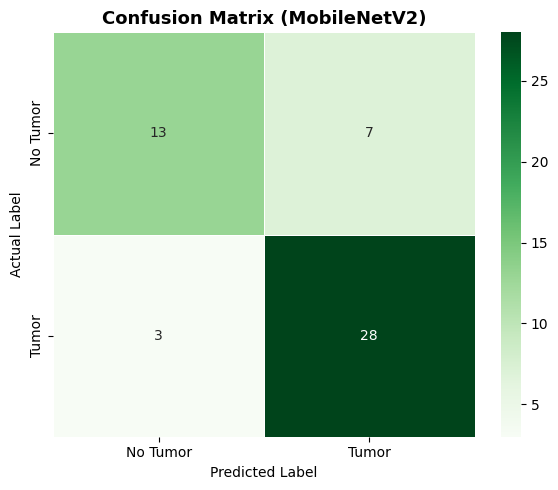


MobileNetV2 model saved!


In [20]:
# ─────────────────────────────────────────────
# STEP 16: BONUS - Transfer Learning (MobileNetV2)
# ─────────────────────────────────────────────
print("\n" + "="*50)
print("Starting TRANSFER LEARNING Experiment...")
print("="*50 + "\n")

# 1. Load the pre-trained model (without its final classification layers)
base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet'
)

# 2. Freeze the base model so we don't destroy its learned features
base_model.trainable = False

# 3. Add our own custom classification head
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)
predictions = Dense(1, activation='sigmoid')(x)

# 4. Combine into a new model
model_mobilenet = Model(inputs=base_model.input, outputs=predictions, name='MobileNetV2_BrainTumor')

model_mobilenet.compile(
    optimizer=Adam(learning_rate=0.0001), # Lower learning rate for transfer learning
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# 5. Train it using the EXACT same data generators!
history_mobilenet = model_mobilenet.fit(
    train_generator,
    epochs=15, # Usually converges faster
    validation_data=val_generator,
    class_weight=class_weights, # Using the same weights
    verbose=1
)

# 6. Evaluate MobileNetV2 on the unseen Test Set
print("\n" + "="*50)
print("MobileNetV2 Evaluation on Test Set")
print("="*50)

y_pred_prob_mn = model_mobilenet.predict(X_test, verbose=0).flatten()
y_pred_mn = (y_pred_prob_mn >= 0.5).astype(int)

test_loss_mn, test_acc_mn = model_mobilenet.evaluate(X_test, y_test, verbose=0)
precision_mn = precision_score(y_test, y_pred_mn)
recall_mn    = recall_score(y_test, y_pred_mn)
f1_mn        = f1_score(y_test, y_pred_mn)

print(f"\n  MobileNetV2 Test Accuracy : {test_acc_mn:.4f} ({test_acc_mn*100:.2f}%)")
print(f"  MobileNetV2 Precision      : {precision_mn:.4f}")
print(f"  MobileNetV2 Recall         : {recall_mn:.4f}")
print(f"  MobileNetV2 F1-Score       : {f1_mn:.4f}")

print("\nMobileNetV2 Classification Report:")
print(classification_report(y_test, y_pred_mn, target_names=['No Tumor', 'Tumor']))

# 7. Plot MobileNetV2 Confusion Matrix
def plot_mobilenet_cm(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', # Using green to distinguish from custom CNN
                xticklabels=['No Tumor', 'Tumor'],
                yticklabels=['No Tumor', 'Tumor'],
                linewidths=0.5, ax=ax)
    ax.set_title('Confusion Matrix (MobileNetV2)', fontweight='bold', fontsize=13)
    ax.set_ylabel('Actual Label')
    ax.set_xlabel('Predicted Label')
    plt.tight_layout()
    plt.savefig("confusion_matrix_mobilenet.png", dpi=150, bbox_inches='tight')
    plt.show()

plot_mobilenet_cm(y_test, y_pred_mn)

# 8. Save the better model!
model_mobilenet.save("brain_tumor_model_mobilenet.keras")
print("\nMobileNetV2 model saved!")

In [21]:
from google.colab import files
files.download("brain_tumor_model_mobilenet.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>